In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
import math
import scipy

In [4]:
# Load data from dumbs
source_dir = "cascadeTof"

rawdata = pd.read_csv(source_dir+"/TOF_rawdata_dumb.csv", sep='\t')
rawdata_bin = rawdata["Unnamed: 0"]
rawdata_s631 = rawdata["Raw counts [counts/bin]  631 mm tube"]
rawdata_s460 = rawdata["Raw counts [counts/bin] 460 mm tube"]

processeddata = pd.read_csv(source_dir+"/TOF_processed_dumb.csv", sep='\t')
v_s631 = processeddata["v [m/s] 631 mm tube"]
v_s460 = processeddata["v [m/s] 460 mm tube"]
pdata_s631 = processeddata["Processed counts [counts/(m/s)] 631 mm tube"]
pdata_s460 = processeddata["Processed counts [counts/(m/s)] 460 mm tube"]

rebinneddata = pd.read_csv(source_dir+"/TOF_rebinned_dumb.csv", sep='\t')
v_rebinned = rebinneddata["v [m/s]"]
rdata_s631 = rebinneddata["Counts [counts/(m/s)] 631 mm tube"]
rdata_s460 = rebinneddata["Counts [counts/(m/s)] 460 mm tube"]
rdata_s631_err = rebinneddata["Counts error [counts/(m/s)] 631 mm tube"]
rdata_s460_err = rebinneddata["Counts error [counts/(m/s)] 460 mm tube"]

# Scalar data from past analysis
darkcounts_s631 =      36.5696969
darkcounts_s631_err =   0.3602967
darkcounts_s460 =      34.1606060
darkcounts_s460_err =   0.3310645

In [ ]:
class RawTOFPoint:
    def __init__(self, 
            index, 
            N_bin, 
            s, 
            label = None,
            darkcounts = 0.0, 
            darkcounts_err = 0.0,
            delta_t = 0.0,
            delta_t_err = 0.0,
            convolution_t = 0.0,
            convolution_t_err = 0.0):
        if s < 0.001: raise ValueError("The length of the TOF tube s [mm] must be positive")
        self.index = index
        self.s = s + 8.0 # chopper padding is 8 mm
        self.label = label
        self.bin_number = index
        self.N_bin = N_bin - darkcounts
        self.N_bin_err = np.sqrt( N_bin + darkcounts_err**2 ) # Gaussian error propagation, err(N_bin) = sqrt(N_bin); poisson
        self.t = self.index * 0.1 - delta_t - convolution_t
        self.t_err = np.sqrt( delta_t_err**2 + convolution_t_err**2 )
        self.N_t = self.N_bin *10 # 10 = 4000 bins / 400 ms
        self.N_t_err = self.N_bin_err *10
        if self.t > 0.000001: 
            self.v = self.s/self.t
            self.v_err = self.s/self.t**2 *self.t_err
        else:    
            self.v = float('nan')
            self.v_err = float('nan')
        self.N_v = self.N_t * self.t**2/self.s
        self.N_v_err = np.sqrt( ( self.N_t_err * self.t**2/self.s )**2 + ( self.t_err * self.N_t *2*self.t/self.s )**2 )


class RawTOFPointList(list):
    def __init__(self, 
            N_bin_list, 
            s, 
            label = None,
            darkcounts = 0.0, 
            darkcounts_err = 0.0,
            delta_t = 0.0,
            delta_t_err = 0.0,
            convolution_t = 0.0,
            convolution_t_err = 0.0):
        super().__init__()
        self.length = len(N_bin_list)
        for i in range(self.length):
            self.append(RawTOFPoint(
                index = i, 
                N_bin = N_bin_list[i], 
                s = s, 
                label = label,
                darkcounts = darkcounts, 
                darkcounts_err = darkcounts_err,
                delta_t = delta_t,
                delta_t_err = delta_t_err,
                convolution_t = convolution_t,
                convolution_t_err = convolution_t_err
            ))
        self.s = s
        self.label = label

    @property
    def bin_number(self):
        a = []
        for i in range(self.length):
            a.append(self[i].bin_number)
        return a

    @property
    def N_bin(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_bin)
        return a

    @property
    def N_bin_err(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_bin_err)
        return a

    @property
    def t(self):
        a = []
        for i in range(self.length):
            a.append(self[i].t)
        return a

    @property
    def t_err(self):
        a = []
        for i in range(self.length):
            a.append(self[i].t_err)
        return a

    @property
    def N_t(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_t)
        return a

    @property
    def N_t_err(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_t_err)
        return a

    @property
    def v(self):
        a = []
        for i in range(self.length):
            a.append(self[i].v)
        return a

    @property
    def v_err(self):
        a = []
        for i in range(self.length):
            a.append(self[i].v_err)
        return a

    @property
    def N_v(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_v)
        return a

    @property
    def N_v_err(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_v_err)
        return a


In [56]:
class RebinnedTOFPoint:
    def __init__(self, 
            index, 
            origin_indices_list,
            v,
            N_v,
            N_v_err, 
            s, 
            label = None,
):

        self.index = index
        self.s = s # chopper padding already included
        self.label = label
        self.origin_indices_list = origin_indices_list
        self.origin_number = len(self.origin_indices_list)
        self.v = v
        self.v_err = None
        self.N_v = N_v
        self.N_v_err = N_v_err



class RebinnedTOFPointList(list):
    def __init__(self, 
            raw_tof_point_list, 
            v_min,
            v_max,
            v_step,
            label = None):
        super().__init__()
        self.v_step = v_step
        self.length = int( (v_max-v_min)/v_step )
        self.v_min = v_min
        self.v_max = self.v_min + self.length*self.v_step
        self.s = raw_tof_point_list.s
        self.label = label

        for i in range(self.length):
            current_v = self.v_min + i*self.v_step
            current_index_list = []
            for j in range(raw_tof_point_list.length):
                if raw_tof_point_list[j].v >= current_v and raw_tof_point_list[j].v < current_v + self.v_step:
                    current_index_list.append(raw_tof_point_list[j].index)

            if len(current_index_list) < 1:
                print(f"No values to rebin from in the interval [{current_v};{current_v + self.v_step}[ m/s")
                self.append(RebinnedTOFPoint(
                    index = i, 
                    s = self.s, 
                    label = self.label,
                    origin_indices_list = current_index_list,
                    v = current_v + 0.5 * self.v_step,
                    N_v = 0,
                    N_v_err = float('nan')
                ))
            
            else:
                rebin_N = []
                weights = []
                for i in current_index_list:
                    rebin_N.append( raw_tof_point_list[i].N_v )
                    weights.append( 1 / (raw_tof_point_list[i].N_v_err**2) )
                rebin_N = np.array(rebin_N)
                weights = np.array(weights)

                self.append(RebinnedTOFPoint(
                    index = i, 
                    s = self.s, 
                    label = self.label,
                    origin_indices_list = current_index_list,
                    v = current_v + 0.5 * self.v_step,
                    N_v = np.sum( rebin_N * weights ) / np.sum(weights),
                    N_v_err = 1 / np.sqrt( np.sum(weights) )
                ))



    @property
    def origin_number(self):
        a = []
        for i in range(self.length):
            a.append(self[i].origin_number)
        return a

    @property
    def v(self):
        a = []
        for i in range(self.length):
            a.append(self[i].v)
        return a

    @property
    def v_err(self):
        a = []
        for i in range(self.length):
            a.append(self[i].v_err)
        return a

    @property
    def N_v(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_v)
        return a

    @property
    def N_v_err(self):
        a = []
        for i in range(self.length):
            a.append(self[i].N_v_err)
        return a

No values to rebin from in the interval [18.85;18.900000000000002[ m/s
No values to rebin from in the interval [19.25;19.3[ m/s
No values to rebin from in the interval [19.55;19.6[ m/s
No values to rebin from in the interval [19.85;19.900000000000002[ m/s
No values to rebin from in the interval [15.600000000000001;15.650000000000002[ m/s
No values to rebin from in the interval [16.25;16.3[ m/s
No values to rebin from in the interval [16.6;16.650000000000002[ m/s
No values to rebin from in the interval [16.9;16.95[ m/s
No values to rebin from in the interval [17.15;17.2[ m/s
No values to rebin from in the interval [17.4;17.45[ m/s
No values to rebin from in the interval [17.6;17.650000000000002[ m/s
No values to rebin from in the interval [17.8;17.85[ m/s
No values to rebin from in the interval [18.15;18.2[ m/s
No values to rebin from in the interval [18.3;18.35[ m/s
No values to rebin from in the interval [18.5;18.55[ m/s
No values to rebin from in the interval [18.65;18.7[ m/s
No valu

Text(0.5, 1.0, 'Rebinned TOF spectra for delta_t = 24.0 ms')

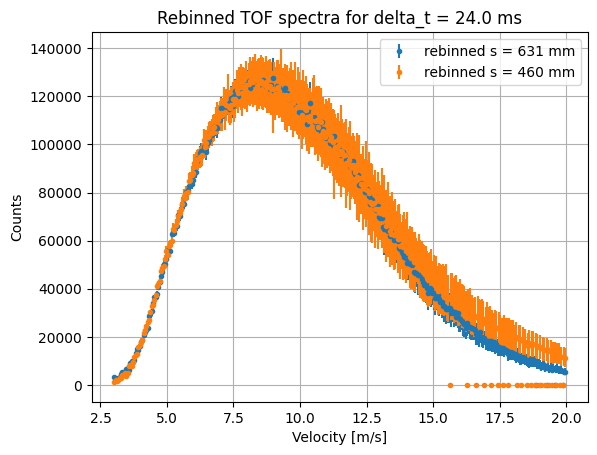

In [119]:
delta_t = 24.0
v_max = 20.0
v_min = 3.0
v_step = 0.05
convolution_t = 5.0
convolution_t_err = 4.0

rawTOF_s631 = RawTOFPointList(rawdata_s631, 
                         s=631, 
                         label = "s = 631 mm", 
                         darkcounts=darkcounts_s631,
                         darkcounts_err=darkcounts_s631_err,
                         delta_t=delta_t,
                         delta_t_err=0.0,
                         convolution_t=convolution_t,
                         convolution_t_err=convolution_t_err)

rebinnedTOF_s631 = RebinnedTOFPointList(rawTOF_s631,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "rebinned s = 631 mm")

rawTOF_s460 = RawTOFPointList(rawdata_s460, 
                         s=460, 
                         label = "s = 460 mm", 
                         darkcounts=darkcounts_s460,
                         darkcounts_err=darkcounts_s460_err,
                         delta_t=delta_t,
                         delta_t_err=0.0,
                         convolution_t=convolution_t,
                         convolution_t_err=convolution_t_err)

rebinnedTOF_s460 = RebinnedTOFPointList(rawTOF_s460,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "rebinned s = 460 mm")


plt.errorbar(rebinnedTOF_s631.v, rebinnedTOF_s631.N_v, rebinnedTOF_s631.N_v_err, label= rebinnedTOF_s631.label, fmt='.')
plt.errorbar(rebinnedTOF_s460.v, rebinnedTOF_s460.N_v, rebinnedTOF_s460.N_v_err, label= rebinnedTOF_s460.label, fmt='.')
plt.xlabel("Velocity [m/s]")
plt.ylabel("Counts")
plt.grid(True)
plt.legend()
plt.title(f"Rebinned TOF spectra for delta_t = {delta_t} ms")

In [115]:
# chi squared, or some other (at this point I don't care anymore) test
delta_t_min, delta_t_max, delta_t_n = 20.0, 28.0, 150
delta_t_list = np.linspace(delta_t_min, delta_t_max, delta_t_n)

v_max = 12.0
v_min = 6.0
v_step = 0.05
convolution_t = 5.0
convolution_t_err = 4.0

chisqr = []
for delta_t in delta_t_list:
    rawTOF_s631 = RawTOFPointList(rawdata_s631, 
                            s=631, 
                            label = "s = 631 mm", 
                            darkcounts=darkcounts_s631,
                            darkcounts_err=darkcounts_s631_err,
                            delta_t=delta_t,
                            delta_t_err=0.0,
                            convolution_t=convolution_t,
                            convolution_t_err=convolution_t_err)

    rebinnedTOF_s631 = RebinnedTOFPointList(rawTOF_s631,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "rebinned s = 631 mm")

    rawTOF_s460 = RawTOFPointList(rawdata_s460, 
                            s=460, 
                            label = "s = 460 mm", 
                            darkcounts=darkcounts_s460,
                            darkcounts_err=darkcounts_s460_err,
                            delta_t=delta_t,
                            delta_t_err=0.0,
                            convolution_t=convolution_t,
                            convolution_t_err=convolution_t_err)

    rebinnedTOF_s460 = RebinnedTOFPointList(rawTOF_s460,
                                    v_min = v_min,
                                    v_max = v_max,
                                    v_step = v_step,
                                    label = "rebinned s = 460 mm")

    data = np.array(rebinnedTOF_s631.N_v)
    model = np.array(rebinnedTOF_s460.N_v)
    data_err = np.array(rebinnedTOF_s631.N_v_err)
    model_err = np.array(rebinnedTOF_s460.N_v_err)

    chisqr.append( np.sum( (data-model)**2 / (model_err**2 + data_err**2)) )








Popt
[24.16723939  1.5866504   5.60262845]
Pcov
[[ 1.27889312e-04 -3.06053411e-05  9.84044297e-05]
 [-3.06053411e-05  2.90362093e-04 -1.56126323e-03]
 [ 9.84044297e-05 -1.56126323e-03  1.52149641e-02]]
perr
[0.01130882 0.01704001 0.12334895]


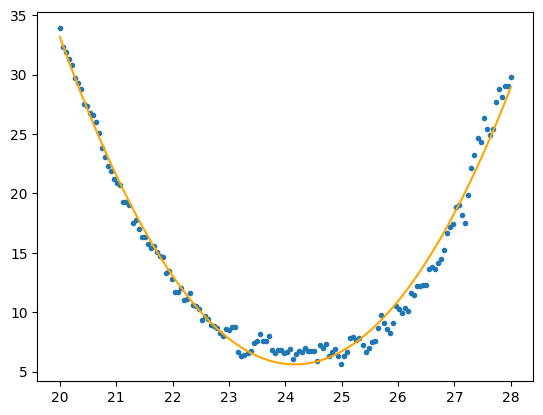

In [116]:
def quadratic_func(x, c, a, d, k=0):
    return a * (x-c)**2 + k * (x-c) + d

# making an initial guess
a0 = 10
k0 = 0.0
d0 = 100  
c0 = 29.0

p0 = [c0, a0, d0]

popt, pcov = scipy.optimize.curve_fit(quadratic_func, xdata=delta_t_list, ydata=chisqr, p0=p0)
perr = np.sqrt(np.diag(pcov)) # errors

print('Popt')
print(popt)
print('Pcov')
print(pcov)
print('perr')
print(perr)

plt.scatter(delta_t_list, chisqr, marker='.')
plt.plot(delta_t_list, quadratic_func(delta_t_list, *popt), label="fit", color='orange')